In [1]:
import pandas as pd

df = pd.read_csv("../data/raw_dataset.csv")

df.head()

,project_id,project_type,project_scale,project_duration_years,complexity_index,initial_investment,tax_rate,risk_index,year,inflation_rate,market_growth_rate,revenue,operating_cost,capex,working_capital,cash_flow
0,P0001,Manufacturing,Medium,9,0.68,97927899.89,0.17,0.67,1,0.06,0.01,25091835.95,18278559.30,5887041.96,2220759.40,-2395752.07
1,P0001,Manufacturing,Medium,9,0.68,97927899.89,0.17,0.67,2,0.07,0.04,31515722.37,21472504.85,2156997.60,2711995.95,5588259.78
2,P0001,Manufacturing,Medium,9,0.68,97927899.89,0.17,0.67,3,0.09,0.08,47433995.67,36251329.00,4425897.72,4174260.40,3249734.67
3,P0001,Manufacturing,Medium,9,0.68,97927899.89,0.17,0.67,4,0.05,0.06,48164969.53,35344119.92,1939175.23,4229398.99,8667076.68
4,P0001,Manufacturing,Medium,9,0.68,97927899.89,0.17,0.67,5,0.06,0.12,67876067.92,49986826.23,4078154.71,5751746.19,9068670.71


In [2]:
df = df.sort_values(
    ["project_id", "year"]
).reset_index(drop=True)

df[["project_id", "year", "cash_flow"]].head(15)

,project_id,year,cash_flow
0,P0001,1,-2395752.07
1,P0001,2,5588259.78
2,P0001,3,3249734.67
3,P0001,4,8667076.68
4,P0001,5,9068670.71
5,P0001,6,10906457.69
6,P0001,7,7209321.18
7,P0001,8,10192767.52
8,P0001,9,10402911.22
9,P0002,1,-2848384.67


In [3]:
sequence_features = [
    "cash_flow",
    "inflation_rate",
    "market_growth_rate"
]

In [4]:
sequence_length = 3

X_sequences = []
y_sequences = []
project_sequence_ids = []

for project_id, project in df.groupby("project_id"):

    project = project.sort_values("year")

    values = project[sequence_features].values
    cash_flows = project["cash_flow"].values

    if len(project) <= sequence_length:
        continue

    for i in range(len(project) - sequence_length):

        X_sequences.append(
            values[i:i + sequence_length]
        )

        y_sequences.append(
            cash_flows[i + sequence_length]
        )

        project_sequence_ids.append(project_id)

In [5]:
import numpy as np

X_sequences = np.array(X_sequences)
y_sequences = np.array(y_sequences)

print("X shape:", X_sequences.shape)
print("y shape:", y_sequences.shape)

X shape: (1765, 3, 3)
y shape: (1765,)


In [6]:
print("One input sequence:")
print(X_sequences[0])

print("\nTarget cash flow:")
print(y_sequences[0])

One input sequence:
[[-2.39575207e+06  6.00000000e-02  1.00000000e-02]
 [ 5.58825978e+06  7.00000000e-02  4.00000000e-02]
 [ 3.24973467e+06  9.00000000e-02  8.00000000e-02]]

Target cash flow:
8667076.68


In [7]:
from sklearn.model_selection import train_test_split

project_ids = df["project_id"].unique().to_numpy()

train_projects, test_projects = train_test_split(
    project_ids,
    test_size=0.20,
    random_state=42
)

print("Training projects:", len(train_projects))
print("Testing projects:", len(test_projects))

Training projects: 400
Testing projects: 100


In [8]:
train_df = df[df["project_id"].isin(train_projects)].copy()
test_df = df[df["project_id"].isin(test_projects)].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

Training rows: 2620
Testing rows: 645


In [9]:
def create_sequences(data, sequence_length=3):

    X = []
    y = []
    project_ids = []

    for project_id, project in data.groupby("project_id"):

        project = project.sort_values("year")

        values = project[sequence_features].values
        cash_flows = project["cash_flow"].values

        if len(project) <= sequence_length:
            continue

        for i in range(len(project) - sequence_length):

            X.append(
                values[i:i + sequence_length]
            )

            y.append(
                cash_flows[i + sequence_length]
            )

            project_ids.append(project_id)

    return (
        np.array(X),
        np.array(y),
        np.array(project_ids)
    )

In [10]:
X_train, y_train, train_sequence_projects = create_sequences(
    train_df,
    sequence_length=3
)

X_test, y_test, test_sequence_projects = create_sequences(
    test_df,
    sequence_length=3
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1420, 3, 3)
y_train: (1420,)

X_test: (345, 3, 3)
y_test: (345,)


In [11]:
# ---------------------------------------------------------------------------
# SHAP BACKGROUND DATA
# ---------------------------------------------------------------------------
#
# SHAP needs representative examples from the same input distribution
# used to train the LSTM.
#
# X_train already contains the historical 3-year sequences used by
# the LSTM during training:
#
#     (samples, 3 years, 3 features)
#
# We keep a smaller representative subset because SHAP does not need
# all training samples to establish its reference distribution.
# ---------------------------------------------------------------------------

import numpy as np
import os


# Use a fixed random seed so that the background dataset is reproducible.
np.random.seed(42)

BACKGROUND_SIZE = 100

# Randomly select representative training sequences.
background_indices = np.random.choice(
    len(X_train),
    size=min(BACKGROUND_SIZE, len(X_train)),
    replace=False
)

shap_background = X_train[background_indices].astype(np.float32)

print("SHAP background shape:", shap_background.shape)

SHAP background shape: (100, 3, 3)


In [12]:
# ---------------------------------------------------------------------------
# Save the SHAP background dataset.
#
# The V2 explainability service will load this file when the application
# needs to generate an explanation. This avoids rebuilding the training
# dataset every time the API receives a request.
# ---------------------------------------------------------------------------

BACKGROUND_PATH = "shap_background.npy"

np.save(
    BACKGROUND_PATH,
    shap_background
)

print("Saved SHAP background to:", BACKGROUND_PATH)

Saved SHAP background to: shap_background.npy


In [13]:
overlap = set(train_sequence_projects) & set(test_sequence_projects)

print("Project overlap:", len(overlap))

Project overlap: 0


In [14]:
from sklearn.preprocessing import StandardScaler

X_scaler = StandardScaler()

X_train_2d = X_train.reshape(-1, X_train.shape[2])
X_test_2d = X_test.reshape(-1, X_test.shape[2])

X_train_scaled = X_scaler.fit_transform(X_train_2d)
X_test_scaled = X_scaler.transform(X_test_2d)

X_train_scaled = X_train_scaled.reshape(X_train.shape)
X_test_scaled = X_test_scaled.reshape(X_test.shape)

In [15]:
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.reshape(-1, 1)
).ravel()

y_test_scaled = y_scaler.transform(
    y_test.reshape(-1, 1)
).ravel()

In [16]:
print("X_train_scaled:", X_train_scaled.shape)
print("y_train_scaled:", y_train_scaled.shape)

print("\nX_test_scaled:", X_test_scaled.shape)
print("y_test_scaled:", y_test_scaled.shape)

X_train_scaled: (1420, 3, 3)
y_train_scaled: (1420,)

X_test_scaled: (345, 3, 3)
y_test_scaled: (345,)


In [17]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

In [18]:
model = Sequential([
    LSTM(
        32,
        input_shape=(X_train_scaled.shape[1], X_train_scaled.shape[2])
    ),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

c:\Users\DELL 3530\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,153 (20.13 KB)

 Trainable params: 5,153 (20.13 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history = model.fit(
    X_train_scaled,
    y_train_scaled,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.8236 - val_loss: 0.3948
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3564 - val_loss: 0.2185
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2301 - val_loss: 0.1771
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1922 - val_loss: 0.1527
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1653 - val_loss: 0.1315
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1495 - val_loss: 0.1178
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1362 - val_loss: 0.1081
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1298 - val_loss: 0.1042
Epoch 9/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1254 - val_loss: 0.1019
Epoch 10/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1242 - val_loss: 0.1006
Epoch 11/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1239 - val_loss: 0.1007
Epoch 12/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss:

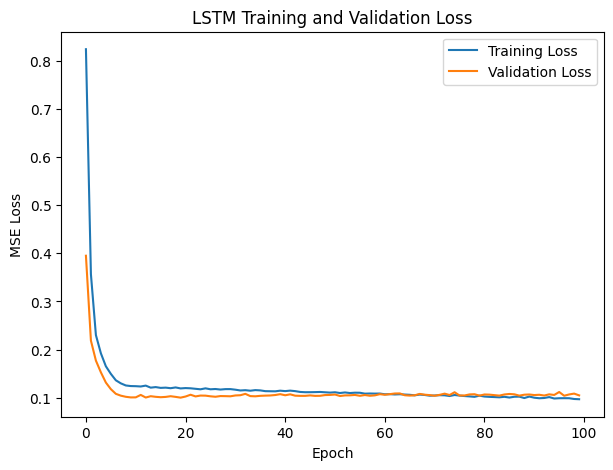

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()

plt.show()

In [21]:
y_pred_scaled = model.predict(
    X_test_scaled
).ravel()

y_pred = y_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step


In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("LSTM Results")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

LSTM Results
MAE : 2369710.989449275
RMSE: 3541181.494195194
R²  : 0.8506726113063127


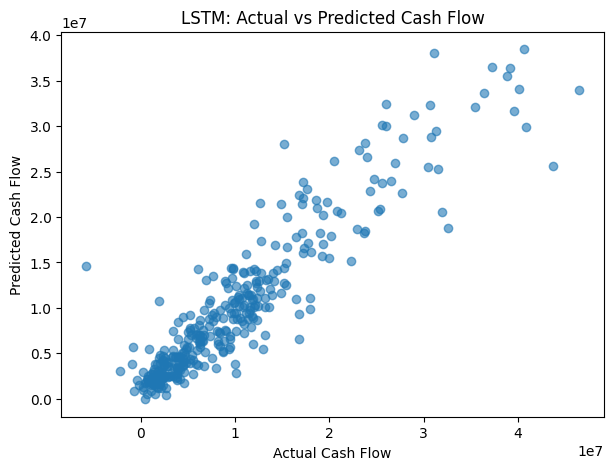

In [23]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

plt.xlabel("Actual Cash Flow")
plt.ylabel("Predicted Cash Flow")
plt.title("LSTM: Actual vs Predicted Cash Flow")

plt.show()

In [24]:
lstm_result = {
    "model": "LSTM",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}

print(lstm_result)

{'model': 'LSTM', 'MAE': 2369710.989449275, 'RMSE': np.float64(3541181.494195194), 'R2': 0.8506726113063127}


BBN

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3265 entries, 0 to 3264
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   project_id              3265 non-null   str    
 1   project_type            3265 non-null   str    
 2   project_scale           3265 non-null   str    
 3   project_duration_years  3265 non-null   int64  
 4   complexity_index        3265 non-null   float64
 5   initial_investment      3265 non-null   float64
 6   tax_rate                3265 non-null   float64
 7   risk_index              3265 non-null   float64
 8   year                    3265 non-null   int64  
 9   inflation_rate          3265 non-null   float64
 10  market_growth_rate      3265 non-null   float64
 11  revenue                 3265 non-null   float64
 12  operating_cost          3265 non-null   float64
 13  capex                   3265 non-null   float64
 14  working_capital         3265 non-null   float64
 15

In [26]:
print("Categorical variables:")
for col in df.select_dtypes(include=["str", "object"]).columns:
    print(f"\n{col}:")
    print(df[col].unique())

print("\nNumerical variables:")
display(df.select_dtypes(include=np.number).describe().T[["min", "max", "mean", "std"]])

Categorical variables:

project_id:
<ArrowStringArray>
['P0001', 'P0002', 'P0003', 'P0004', 'P0005', 'P0006', 'P0007', 'P0008',
 'P0009', 'P0010',
 ...
 'P0491', 'P0492', 'P0493', 'P0494', 'P0495', 'P0496', 'P0497', 'P0498',
 'P0499', 'P0500']
Length: 500, dtype: str

project_type:
<ArrowStringArray>
[ 'Manufacturing',     'Healthcare',         'Energy', 'Infrastructure',
    'Real Estate',     'Technology']
Length: 6, dtype: str

project_scale:
<ArrowStringArray>
['Medium', 'Large', 'Small']
Length: 3, dtype: str

Numerical variables:


,min,max,mean,std
project_duration_years,3.00,1.000000e+01,7.335069e+00,2.151965e+00
complexity_index,0.10,9.500000e-01,5.378683e-01,1.787903e-01
initial_investment,5138673.95,3.852187e+08,9.918074e+07,7.495220e+07
tax_rate,0.15,3.500000e-01,2.488882e-01,3.907346e-02
risk_index,0.10,9.000000e-01,4.980490e-01,1.773218e-01
year,1.00,1.000000e+01,4.167534e+00,2.438292e+00
inflation_rate,0.02,1.100000e-01,5.520368e-02,1.798939e-02
market_growth_rate,-0.08,1.500000e-01,5.493109e-02,3.499742e-02
revenue,2051367.15,2.553143e+08,4.290279e+07,3.147631e+07
operating_cost,950422.13,1.480694e+08,2.686972e+07,2.020513e+07


Risk:
Low / Medium / High

Complexity:
Low / Medium / High

Inflation:
Low / Medium / High

In [27]:
bbn_candidates = [
    "complexity_index",
    "risk_index",
    "inflation_rate",
    "market_growth_rate",
    "revenue",
    "operating_cost",
    "working_capital",
    "cash_flow"
]

display(df[bbn_candidates].quantile([0.25, 0.50, 0.75]).T)

,0.25,0.50,0.75
complexity_index,0.41,0.55,0.65
risk_index,0.38,0.50,0.63
inflation_rate,0.04,0.05,0.07
market_growth_rate,0.03,0.05,0.08
revenue,20151170.46,34971362.01,58128185.85
operating_cost,12402646.63,21975997.46,36153484.30
working_capital,1489200.79,2757863.31,4895963.88
cash_flow,1681005.84,5629000.30,11680937.95


## complexity calculation 

In [28]:
# ---------------------------------------------------------------------------
# REPLACE THE OLD SYNTHETIC COMPLEXITY INDEX
# ---------------------------------------------------------------------------
#
# The original dataset contains a synthetic complexity_index.
# We now replace it with the deterministic complexity score calculated from:
#
#   - project scale
#   - project duration
#   - initial investment
#
# The same calculation is used later for new projects entering the DSS.
# ---------------------------------------------------------------------------

import sys
from pathlib import Path

# Locate the machine_learning directory from the notebook location.
current_path = Path.cwd()

machine_learning_dir = None

for path in [current_path, *current_path.parents]:
    if (path / "v2" / "services").exists():
        machine_learning_dir = path
        break

if machine_learning_dir is None:
    raise FileNotFoundError(
        "Could not locate machine_learning/v2/services."
    )

v2_dir = machine_learning_dir / "v2"

if str(v2_dir) not in sys.path:
    sys.path.insert(0, str(v2_dir))

from services.complexity_assessor import (
    calculate_historical_complexity
)

# Calculate the new complexity once for every historical project.
complexity_df = calculate_historical_complexity()

# Replace the old synthetic complexity value.
#
# complexity_df has one row per project.
# df has one row per project-year.
# Therefore, merge the project-level complexity onto every year.
df = df.drop(
    columns=["complexity_index"]
).merge(
    complexity_df[
        ["project_id", "complexity_index"]
    ],
    on="project_id",
    how="left"
)

# Safety check.
missing_complexity = df["complexity_index"].isna().sum()

print("Missing complexity values:", missing_complexity)
print("\nNew complexity statistics:")
display(df["complexity_index"].describe())

Missing complexity values: 0

New complexity statistics:


count    3265.000000
mean        0.522147
std         0.206193
min         0.036000
25%         0.367200
50%         0.518000
75%         0.676400
max         0.996400
Name: complexity_index, dtype: float64

In [29]:
# Create BBN states using ONLY the training projects
# The learned boundaries are then applied to the full dataset.

bbn_continuous = [
    "complexity_index",
    "risk_index",
    "inflation_rate",
    "market_growth_rate",
    "revenue",
    "operating_cost",
    "working_capital",
    "cash_flow"
]

# Store the training-derived boundaries
bbn_bins = {}

train_df = df[df["project_id"].isin(train_projects)].copy()

for col in bbn_continuous:

    # Learn quantile boundaries ONLY from training data
    q1 = train_df[col].quantile(1/3)
    q2 = train_df[col].quantile(2/3)

    bins = [-np.inf, q1, q2, np.inf]

    # Make sure the boundaries are valid
    if len(np.unique(bins)) != 4:
        raise ValueError(
            f"Cannot create 3 states for '{col}'. "
            f"Training quantiles are not unique."
        )

    bbn_bins[col] = bins

    # Apply the training-derived boundaries to ALL rows
    df[f"{col}_state"] = pd.cut(
        df[col],
        bins=bins,
        labels=["Low", "Medium", "High"],
        include_lowest=True
    )

display(
    df[
        [col + "_state" for col in bbn_continuous]
    ].head()
)

,complexity_index_state,risk_index_state,inflation_rate_state,market_growth_rate_state,revenue_state,operating_cost_state,working_capital_state,cash_flow_state
0,High,High,Medium,Low,Medium,Medium,Medium,Low
1,High,High,High,Low,Medium,Medium,Medium,Medium
2,High,High,High,High,Medium,High,High,Medium
3,High,High,Low,Medium,Medium,High,High,Medium
4,High,High,Medium,High,High,High,High,Medium


In [30]:
print("Training-derived BBN boundaries:\n")

for col, bins in bbn_bins.items():
    print(f"{col}:")
    print(f"  Low    : (-inf, {bins[1]:.4f}]")
    print(f"  Medium : ({bins[1]:.4f}, {bins[2]:.4f}]")
    print(f"  High   : ({bins[2]:.4f}, inf)")
    print()

Training-derived BBN boundaries:

complexity_index:
  Low    : (-inf, 0.4068]
  Medium : (0.4068, 0.6332]
  High   : (0.6332, inf)

risk_index:
  Low    : (-inf, 0.4300]
  Medium : (0.4300, 0.5800]
  High   : (0.5800, inf)

inflation_rate:
  Low    : (-inf, 0.0500]
  Medium : (0.0500, 0.0600]
  High   : (0.0600, inf)

market_growth_rate:
  Low    : (-inf, 0.0400]
  Medium : (0.0400, 0.0700]
  High   : (0.0700, inf)

revenue:
  Low    : (-inf, 24233560.6600]
  Medium : (24233560.6600, 48998491.9200]
  High   : (48998491.9200, inf)

operating_cost:
  Low    : (-inf, 15530791.6300]
  Medium : (15530791.6300, 30760171.0100]
  High   : (30760171.0100, inf)

working_capital:
  Low    : (-inf, 1864011.6300]
  Medium : (1864011.6300, 4019684.2900]
  High   : (4019684.2900, inf)

cash_flow:
  Low    : (-inf, 2872113.7000]
  Medium : (2872113.7000, 9161226.8100]
  High   : (9161226.8100, inf)



In [31]:
for col in bbn_continuous:
    print(f"\n{col}")
    print(df[f"{col}_state"].value_counts().sort_index())


complexity_index
complexity_index_state
Low       1047
Medium    1146
High      1072
Name: count, dtype: int64

risk_index
risk_index_state
Low       1140
Medium    1090
High      1035
Name: count, dtype: int64

inflation_rate
inflation_rate_state
Low       1647
Medium     680
High       938
Name: count, dtype: int64

market_growth_rate
market_growth_rate_state
Low       1253
Medium    1101
High       911
Name: count, dtype: int64

revenue
revenue_state
Low       1072
Medium    1088
High      1105
Name: count, dtype: int64

operating_cost
operating_cost_state
Low       1077
Medium    1099
High      1089
Name: count, dtype: int64

working_capital
working_capital_state
Low       1069
Medium    1100
High      1096
Name: count, dtype: int64

cash_flow
cash_flow_state
Low       1105
Medium    1067
High      1093
Name: count, dtype: int64


In [32]:
corr_cols = [
    "complexity_index",
    "risk_index",
    "inflation_rate",
    "market_growth_rate",
    "revenue",
    "operating_cost",
    "working_capital",
    "cash_flow"
]

display(df[corr_cols].corr().round(2))

,complexity_index,risk_index,inflation_rate,market_growth_rate,revenue,operating_cost,working_capital,cash_flow
complexity_index,1.00,0.04,0.02,0.04,0.55,0.54,0.48,0.27
risk_index,0.04,1.00,-0.04,0.03,0.06,0.06,0.08,0.02
inflation_rate,0.02,-0.04,1.00,0.01,0.03,0.03,0.02,0.02
market_growth_rate,0.04,0.03,0.01,1.00,0.05,0.05,0.04,0.03
revenue,0.55,0.06,0.03,0.05,1.00,0.96,0.90,0.71
operating_cost,0.54,0.06,0.03,0.05,0.96,1.00,0.85,0.57
working_capital,0.48,0.08,0.02,0.04,0.90,0.85,1.00,0.64
cash_flow,0.27,0.02,0.02,0.03,0.71,0.57,0.64,1.00


In [33]:
print("Risk state vs Cash-flow state")
display(pd.crosstab(df["risk_index_state"], df["cash_flow_state"], normalize="index").round(3))

print("\nRisk state vs Operating-cost state")
display(pd.crosstab(df["risk_index_state"], df["operating_cost_state"], normalize="index").round(3))

Risk state vs Cash-flow state


cash_flow_state,Low,Medium,High
risk_index_state,,,
Low,0.324,0.361,0.315
Medium,0.357,0.282,0.361
High,0.335,0.336,0.329



Risk state vs Operating-cost state


operating_cost_state,Low,Medium,High
risk_index_state,,,
Low,0.340,0.335,0.325
Medium,0.347,0.317,0.336
High,0.300,0.358,0.341


In [34]:
df["cost_ratio"] = df["operating_cost"] / df["revenue"]
df["working_capital_ratio"] = df["working_capital"] / df["revenue"]
df["cash_flow_margin"] = df["cash_flow"] / df["revenue"]

display(
    df.groupby("risk_index_state")[
        ["cost_ratio", "working_capital_ratio", "cash_flow_margin"]
    ].mean().round(4)
)

,cost_ratio,working_capital_ratio,cash_flow_margin
risk_index_state,,,
Low,0.6248,0.0827,0.1391
Medium,0.6250,0.0823,0.1384
High,0.6320,0.0893,0.1403


In [35]:
df_sorted = df.sort_values(["project_id", "year"]).copy()

df_sorted["next_cash_flow"] = (
    df_sorted.groupby("project_id")["cash_flow"].shift(-1)
)

df_sorted["next_revenue"] = (
    df_sorted.groupby("project_id")["revenue"].shift(-1)
)

df_sorted["next_operating_cost"] = (
    df_sorted.groupby("project_id")["operating_cost"].shift(-1)
)

df_sorted["next_cash_flow_margin"] = (
    df_sorted["next_cash_flow"] / df_sorted["next_revenue"]
)

display(
    df_sorted.groupby("risk_index_state")[
        ["next_cash_flow_margin", "next_operating_cost"]
    ].mean().round(4)
)

,next_cash_flow_margin,next_operating_cost
risk_index_state,,
Low,0.2008,2.818511e+07
Medium,0.2034,2.941793e+07
High,0.1991,2.900916e+07


In [36]:
[k for k in globals().keys() if not k.startswith("_")]

['In',
 'Out',
 'get_ipython',
 'exit',
 'quit',
 'open',
 'pd',
 'df',
 'sequence_features',
 'sequence_length',
 'X_sequences',
 'y_sequences',
 'project_sequence_ids',
 'project_id',
 'project',
 'values',
 'cash_flows',
 'i',
 'np',
 'train_test_split',
 'project_ids',
 'train_projects',
 'test_projects',
 'train_df',
 'test_df',
 'create_sequences',
 'X_train',
 'y_train',
 'train_sequence_projects',
 'X_test',
 'y_test',
 'test_sequence_projects',
 'os',
 'BACKGROUND_SIZE',
 'background_indices',
 'shap_background',
 'BACKGROUND_PATH',
 'overlap',
 'StandardScaler',
 'X_scaler',
 'X_train_2d',
 'X_test_2d',
 'X_train_scaled',
 'X_test_scaled',
 'y_scaler',
 'y_train_scaled',
 'y_test_scaled',
 'Sequential',
 'LSTM',
 'Dense',
 'model',
 'history',
 'plt',
 'y_pred_scaled',
 'y_pred',
 'mean_absolute_error',
 'mean_squared_error',
 'r2_score',
 'mae',
 'rmse',
 'r2',
 'lstm_result',
 'col',
 'bbn_candidates',
 'sys',
 'Path',
 'current_path',
 'machine_learning_dir',
 'path',
 'v2

In [37]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("y_pred shape:", y_pred.shape)
print("test_sequence_projects shape:", np.array(test_sequence_projects).shape)

print("\nFirst 10 test projects:")
print(np.array(test_sequence_projects)[:10])

print("\nFirst 10 actual cash flows:")
print(y_test[:10])

print("\nFirst 10 LSTM predictions:")
print(y_pred[:10])

X_test shape: (345, 3, 3)
y_test shape: (345,)
y_pred shape: (345,)
test_sequence_projects shape: (345,)

First 10 test projects:
['P0001' 'P0001' 'P0001' 'P0001' 'P0001' 'P0001' 'P0003' 'P0003' 'P0003'
 'P0003']

First 10 actual cash flows:
[ 8667076.68  9068670.71 10906457.69  7209321.18 10192767.52 10402911.22
  3848599.2   3950990.76  3694721.66  4492148.76]

First 10 LSTM predictions:
[5.2206225e+06 7.4400250e+06 1.0336416e+07 1.0529462e+07 8.8324620e+06
 1.0225514e+07 2.7647780e+06 3.1309690e+06 4.5721330e+06 3.7215535e+06]


In [38]:
import inspect
print(inspect.getsource(create_sequences))

def create_sequences(data, sequence_length=3):

    X = []
    y = []
    project_ids = []

    for project_id, project in data.groupby("project_id"):

        project = project.sort_values("year")

        values = project[sequence_features].values
        cash_flows = project["cash_flow"].values

        if len(project) <= sequence_length:
            continue

        for i in range(len(project) - sequence_length):

            X.append(
                values[i:i + sequence_length]
            )

            y.append(
                cash_flows[i + sequence_length]
            )

            project_ids.append(project_id)

    return (
        np.array(X),
        np.array(y),
        np.array(project_ids)
    )



project_id | target_year | actual_CF | LSTM_predicted_CF : mapping

In [39]:
prediction_rows = []

for project_id, project in test_df.groupby("project_id"):
    project = project.sort_values("year").reset_index(drop=True)

    for i in range(len(project) - sequence_length):
        target_index = i + sequence_length

        prediction_rows.append({
            "project_id": project_id,
            "target_year": project.loc[target_index, "year"],
            "actual_cash_flow": project.loc[target_index, "cash_flow"]
        })

lstm_predictions_df = pd.DataFrame(prediction_rows)

lstm_predictions_df["lstm_predicted_cash_flow"] = y_pred

display(lstm_predictions_df.head(10))

print("Rows:", len(lstm_predictions_df))
print("Predictions:", len(y_pred))

,project_id,target_year,actual_cash_flow,lstm_predicted_cash_flow
0,P0001,4,8667076.68,5220622.5
1,P0001,5,9068670.71,7440025.0
2,P0001,6,10906457.69,10336416.0
3,P0001,7,7209321.18,10529462.0
4,P0001,8,10192767.52,8832462.0
5,P0001,9,10402911.22,10225514.0
6,P0003,4,3848599.20,2764778.0
7,P0003,5,3950990.76,3130969.0
8,P0003,6,3694721.66,4572133.0
9,P0003,7,4492148.76,3721553.5


Rows: 345
Predictions: 345


In [40]:
lstm_predictions_df["cash_flow_deviation"] = (
    (lstm_predictions_df["actual_cash_flow"] -
     lstm_predictions_df["lstm_predicted_cash_flow"])
    / lstm_predictions_df["lstm_predicted_cash_flow"].abs()
)

display(
    lstm_predictions_df[
        [
            "project_id",
            "target_year",
            "actual_cash_flow",
            "lstm_predicted_cash_flow",
            "cash_flow_deviation"
        ]
    ].head(10)
)

print("\nCash-flow deviation summary:")
display(lstm_predictions_df["cash_flow_deviation"].describe())

,project_id,target_year,actual_cash_flow,lstm_predicted_cash_flow,cash_flow_deviation
0,P0001,4,8667076.68,5220622.5,0.660162
1,P0001,5,9068670.71,7440025.0,0.218903
2,P0001,6,10906457.69,10336416.0,0.055149
3,P0001,7,7209321.18,10529462.0,-0.315319
4,P0001,8,10192767.52,8832462.0,0.154012
5,P0001,9,10402911.22,10225514.0,0.017348
6,P0003,4,3848599.20,2764778.0,0.392010
7,P0003,5,3950990.76,3130969.0,0.261907
8,P0003,6,3694721.66,4572133.0,-0.191904
9,P0003,7,4492148.76,3721553.5,0.207063



Cash-flow deviation summary:


count    345.000000
mean       0.044514
std        0.789069
min       -1.898044
25%       -0.234693
50%       -0.007465
75%        0.198126
max       10.360702
Name: cash_flow_deviation, dtype: float64

In [41]:
display(
    lstm_predictions_df["cash_flow_deviation"]
    .quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95])
    .to_frame("cash_flow_deviation")
)

,cash_flow_deviation
0.05,-0.619547
0.10,-0.480689
0.25,-0.234693
0.50,-0.007465
0.75,0.198126
0.90,0.535411
0.95,0.825887


In [42]:
y_train_pred_scaled = model.predict(X_train_scaled, verbose=0)

y_train_pred = y_scaler.inverse_transform(
    y_train_pred_scaled
).flatten()

y_train_actual = y_scaler.inverse_transform(
    y_train_scaled.reshape(-1, 1)
).flatten()

train_cash_flow_deviation = (
    (y_train_actual - y_train_pred)
    / np.abs(y_train_pred)
)

display(
    pd.Series(train_cash_flow_deviation).describe(
        percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    ).to_frame("train_cash_flow_deviation")
)

,train_cash_flow_deviation
count,1420.000000
mean,0.073173
std,1.661130
min,-24.128871
5%,-0.544655
10%,-0.378947
25%,-0.167455
50%,-0.000977
75%,0.183975
90%,0.435336


In [43]:
train_cash_flow_deviation = (
    (y_train_actual - y_train_pred)
    / np.maximum(np.abs(y_train_actual), np.abs(y_train_pred))
)

display(
    pd.Series(train_cash_flow_deviation).describe(
        percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    ).to_frame("train_cash_flow_deviation")
)

,train_cash_flow_deviation
count,1420.000000
mean,-0.029407
std,0.326379
min,-1.998279
5%,-0.544655
10%,-0.378947
25%,-0.167455
50%,-0.000977
75%,0.155388
90%,0.303298


In [44]:
lower_threshold, upper_threshold = np.quantile(
    train_cash_flow_deviation,
    [1/3, 2/3]
)

print("Lower threshold:", lower_threshold)
print("Upper threshold:", upper_threshold)

Lower threshold: -0.112753690734604
Upper threshold: 0.09382402044987069


In [45]:
test_cash_flow_deviation = (
    (lstm_predictions_df["actual_cash_flow"] - lstm_predictions_df["lstm_predicted_cash_flow"])
    / np.maximum(
        np.abs(lstm_predictions_df["actual_cash_flow"]),
        np.abs(lstm_predictions_df["lstm_predicted_cash_flow"])
    )
)

lstm_predictions_df["cash_flow_deviation"] = test_cash_flow_deviation

lstm_predictions_df["cash_flow_evidence"] = pd.cut(
    lstm_predictions_df["cash_flow_deviation"],
    bins=[-np.inf, lower_threshold, upper_threshold, np.inf],
    labels=["Worse", "Near Expected", "Better"]
)

display(
    lstm_predictions_df[
        ["project_id", "target_year", "actual_cash_flow",
         "lstm_predicted_cash_flow", "cash_flow_deviation",
         "cash_flow_evidence"]
    ].head(10)
)

,project_id,target_year,actual_cash_flow,lstm_predicted_cash_flow,cash_flow_deviation,cash_flow_evidence
0,P0001,4,8667076.68,5220622.5,0.397649,Better
1,P0001,5,9068670.71,7440025.0,0.179590,Better
2,P0001,6,10906457.69,10336416.0,0.052266,Near Expected
3,P0001,7,7209321.18,10529462.0,-0.315319,Worse
4,P0001,8,10192767.52,8832462.0,0.133458,Better
5,P0001,9,10402911.22,10225514.0,0.017053,Near Expected
6,P0003,4,3848599.20,2764778.0,0.281614,Better
7,P0003,5,3950990.76,3130969.0,0.207548,Better
8,P0003,6,3694721.66,4572133.0,-0.191904,Worse
9,P0003,7,4492148.76,3721553.5,0.171543,Better


In [46]:
display(
    lstm_predictions_df["cash_flow_evidence"]
    .value_counts()
    .reindex(["Worse", "Near Expected", "Better"])
    .to_frame("count")
)

,count
cash_flow_evidence,
Worse,132
Near Expected,96
Better,117


The LSTM gives us the expected cash flow.
The BBN models the uncertainty/risk around that expectation using observable project/economic conditions.

In [47]:
# ---------------------------------------------------------------------------
# Import the V2 complexity assessor.
#
# The research notebook is located under:
#     machine_learning/Research/final_model/
#
# while the reusable V2 services are located under:
#     machine_learning/v2/services/
#
# Therefore, we explicitly add the V2 directory to Python's module search
# path before importing the complexity assessor.
# ---------------------------------------------------------------------------

import sys
from pathlib import Path

# Find the machine_learning directory from the notebook's working directory.
current_path = Path.cwd()

machine_learning_dir = None

for path in [current_path, *current_path.parents]:
    if (path / "v2" / "services").exists():
        machine_learning_dir = path
        break

if machine_learning_dir is None:
    raise FileNotFoundError(
        "Could not locate the machine_learning/v2/services directory."
    )

v2_dir = machine_learning_dir / "v2"

if str(v2_dir) not in sys.path:
    sys.path.insert(0, str(v2_dir))


from services.complexity_assessor import (
    calculate_historical_complexity,
    build_reference_population
)

print("V2 services path:", v2_dir)

V2 services path: c:\PBL2_Capital_Budgeting\machine_learning\v2


In [48]:
# ---------------------------------------------------------------------------
# Calculate the deterministic complexity index for every historical project.
#
# This replaces the old synthetic/random complexity_index used previously
# by the BBN training process.
# ---------------------------------------------------------------------------

complexity_df = calculate_historical_complexity()

complexity_df.head()

,project_id,complexity_index,scale_score,duration_score,investment_score
0,P0001,0.6410,0.5,0.864,0.606
1,P0002,0.6614,0.5,0.864,0.674
2,P0003,0.6508,1.0,0.748,0.088
3,P0004,0.6926,0.5,0.748,0.894
4,P0005,0.4496,0.5,0.258,0.574


In [49]:
complexity_df["complexity_index"].describe()

count    500.000000
mean       0.487624
std        0.208613
min        0.036000
25%        0.321600
50%        0.484200
75%        0.648200
max        0.996400
Name: complexity_index, dtype: float64

In [50]:
bbn_train_df = df[
    df["project_id"].isin(train_projects)
][
    [
        "project_id",
        "year",
        "complexity_index_state",
        "inflation_rate_state",
        "market_growth_rate_state"
    ]
].copy()

bbn_train_df.head()

,project_id,year,complexity_index_state,inflation_rate_state,market_growth_rate_state
9,P0002,1,High,Low,Low
10,P0002,2,High,Medium,Medium
11,P0002,3,High,High,Medium
12,P0002,4,High,Low,Low
13,P0002,5,High,Low,Medium


In [51]:
bbn_train_evidence = pd.DataFrame({
    "project_id": train_sequence_projects,
    "cash_flow_deviation": train_cash_flow_deviation
})

bbn_train_evidence["cash_flow_evidence"] = pd.cut(
    bbn_train_evidence["cash_flow_deviation"],
    bins=[-np.inf, lower_threshold, upper_threshold, np.inf],
    labels=["Worse", "Near Expected", "Better"]
)

bbn_train_evidence.head()

,project_id,cash_flow_deviation,cash_flow_evidence
0,P0002,0.249730,Better
1,P0002,-0.208538,Worse
2,P0002,-0.283636,Worse
3,P0002,-0.099418,Near Expected
4,P0002,-0.306027,Worse


In [52]:
bbn_train_rows = []

for project_id, project in df[df["project_id"].isin(train_projects)].groupby("project_id"):
    project = project.sort_values("year").reset_index(drop=True)

    for i in range(len(project) - sequence_length):
        target_index = i + sequence_length

        bbn_train_rows.append({
            "project_id": project_id,
            "year": project.loc[target_index, "year"],
            "complexity_state": project.loc[target_index, "complexity_index_state"],
            "inflation_state": project.loc[target_index, "inflation_rate_state"],
            "market_growth_state": project.loc[target_index, "market_growth_rate_state"]
        })

bbn_train_features = pd.DataFrame(bbn_train_rows)

bbn_train_data = bbn_train_features.copy()
bbn_train_data["cash_flow_evidence"] = bbn_train_evidence["cash_flow_evidence"].values

display(bbn_train_data.head())
print("Rows:", len(bbn_train_data))

,project_id,year,complexity_state,inflation_state,market_growth_state,cash_flow_evidence
0,P0002,4,High,Low,Low,Better
1,P0002,5,High,Low,Medium,Worse
2,P0002,6,High,High,High,Worse
3,P0002,7,High,Low,Medium,Near Expected
4,P0002,8,High,High,Medium,Worse


Rows: 1420


In [53]:
import pgmpy

print("pgmpy version:", pgmpy.__version__)

pgmpy version: 1.1.2


P(CashFlowEvidence∣Complexity,Inflation,MarketGrowth)

In [54]:
from pgmpy.models import DiscreteBayesianNetwork

bbn = DiscreteBayesianNetwork([
    ("complexity_state", "cash_flow_evidence"),
    ("inflation_state", "cash_flow_evidence"),
    ("market_growth_state", "cash_flow_evidence")
])

print("BBN structure:")
print(bbn.edges())

BBN structure:
[('complexity_state', 'cash_flow_evidence'), ('inflation_state', 'cash_flow_evidence'), ('market_growth_state', 'cash_flow_evidence')]


c:\Users\DELL 3530\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [55]:
from pgmpy.estimators import MaximumLikelihoodEstimator

mle = MaximumLikelihoodEstimator(
    model=bbn,
    data=bbn_train_data[
        [
            "complexity_state",
            "inflation_state",
            "market_growth_state",
            "cash_flow_evidence"
        ]
    ]
)

cpds = mle.get_parameters()

bbn.add_cpds(*cpds)

print("BBN fitted successfully.")
print("Number of CPDs:", len(bbn.get_cpds()))

c:\Users\DELL 3530\AppData\Local\Programs\Python\Python313\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


BBN fitted successfully.
Number of CPDs: 4


C:\Users\DELL 3530\AppData\Local\Temp\ipykernel_9976\559158025.py:3: FutureWarning: `pgmpy.estimators.MaximumLikelihoodEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteMLE` instead.
  mle = MaximumLikelihoodEstimator(


In [56]:
for cpd in bbn.get_cpds():
    print("=" * 80)
    print(cpd)

+--------------------------+----------+
| complexity_state(High)   | 0.378169 |
+--------------------------+----------+
| complexity_state(Low)    | 0.285915 |
+--------------------------+----------+
| complexity_state(Medium) | 0.335915 |
+--------------------------+----------+
+-----------------------------------+-----+-----------------------------+
| complexity_state                  | ... | complexity_state(Medium)    |
+-----------------------------------+-----+-----------------------------+
| inflation_state                   | ... | inflation_state(Medium)     |
+-----------------------------------+-----+-----------------------------+
| market_growth_state               | ... | market_growth_state(Medium) |
+-----------------------------------+-----+-----------------------------+
| cash_flow_evidence(Better)        | ... | 0.24324324324324326         |
+-----------------------------------+-----+-----------------------------+
| cash_flow_evidence(Near Expected) | ... | 0.37837837

In [57]:
cash_flow_cpd = bbn.get_cpds("cash_flow_evidence")

print(cash_flow_cpd)

+-----------------------------------+-----+-----------------------------+
| complexity_state                  | ... | complexity_state(Medium)    |
+-----------------------------------+-----+-----------------------------+
| inflation_state                   | ... | inflation_state(Medium)     |
+-----------------------------------+-----+-----------------------------+
| market_growth_state               | ... | market_growth_state(Medium) |
+-----------------------------------+-----+-----------------------------+
| cash_flow_evidence(Better)        | ... | 0.24324324324324326         |
+-----------------------------------+-----+-----------------------------+
| cash_flow_evidence(Near Expected) | ... | 0.3783783783783784          |
+-----------------------------------+-----+-----------------------------+
| cash_flow_evidence(Worse)         | ... | 0.3783783783783784          |
+-----------------------------------+-----+-----------------------------+


In [58]:
cpd_table = cash_flow_cpd.get_values()

print("CPD shape:", cpd_table.shape)
print("Number of condition combinations:", cpd_table.shape[1])

pd.DataFrame(
    cpd_table,
    index=cash_flow_cpd.state_names["cash_flow_evidence"]
)

CPD shape: (3, 27)
Number of condition combinations: 27


,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
Better,0.369565,0.177419,0.236364,0.417722,0.362637,0.357143,0.366667,0.354839,0.400000,0.358974,...,0.192308,0.339623,0.26,0.280702,0.407407,0.252747,0.381579,0.461538,0.363636,0.243243
Near Expected,0.304348,0.354839,0.327273,0.341772,0.285714,0.408163,0.366667,0.258065,0.355556,0.384615,...,0.500000,0.377358,0.34,0.298246,0.277778,0.395604,0.368421,0.269231,0.303030,0.378378
Worse,0.326087,0.467742,0.436364,0.240506,0.351648,0.234694,0.266667,0.387097,0.244444,0.256410,...,0.307692,0.283019,0.40,0.421053,0.314815,0.351648,0.250000,0.269231,0.333333,0.378378


In [59]:
state_names = cash_flow_cpd.state_names

for i, combination in enumerate(
    __import__("itertools").product(
        state_names["complexity_state"],
        state_names["inflation_state"],
        state_names["market_growth_state"]
    )
):
    print(
        f"{i:2d}: "
        f"Complexity={combination[0]}, "
        f"Inflation={combination[1]}, "
        f"Market Growth={combination[2]} | "
        f"Better={cpd_table[0, i]:.3f}, "
        f"Near={cpd_table[1, i]:.3f}, "
        f"Worse={cpd_table[2, i]:.3f}"
    )

 0: Complexity=High, Inflation=High, Market Growth=High | Better=0.370, Near=0.304, Worse=0.326
 1: Complexity=High, Inflation=High, Market Growth=Low | Better=0.177, Near=0.355, Worse=0.468
 2: Complexity=High, Inflation=High, Market Growth=Medium | Better=0.236, Near=0.327, Worse=0.436
 3: Complexity=High, Inflation=Low, Market Growth=High | Better=0.418, Near=0.342, Worse=0.241
 4: Complexity=High, Inflation=Low, Market Growth=Low | Better=0.363, Near=0.286, Worse=0.352
 5: Complexity=High, Inflation=Low, Market Growth=Medium | Better=0.357, Near=0.408, Worse=0.235
 6: Complexity=High, Inflation=Medium, Market Growth=High | Better=0.367, Near=0.367, Worse=0.267
 7: Complexity=High, Inflation=Medium, Market Growth=Low | Better=0.355, Near=0.258, Worse=0.387
 8: Complexity=High, Inflation=Medium, Market Growth=Medium | Better=0.400, Near=0.356, Worse=0.244
 9: Complexity=Low, Inflation=High, Market Growth=High | Better=0.359, Near=0.385, Worse=0.256
10: Complexity=Low, Inflation=High,

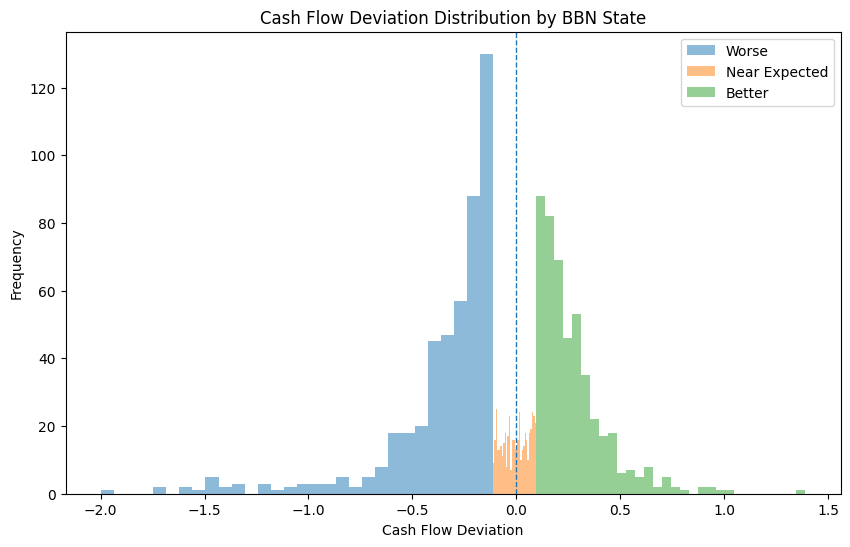

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for state in ["Worse", "Near Expected", "Better"]:
    values = bbn_train_evidence.loc[
        bbn_train_evidence["cash_flow_evidence"] == state,
        "cash_flow_deviation"
    ]

    plt.hist(
        values,
        bins=30,
        alpha=0.5,
        label=state
    )

plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel("Cash Flow Deviation")
plt.ylabel("Frequency")
plt.title("Cash Flow Deviation Distribution by BBN State")
plt.legend()
plt.show()

Worse is strongly left-skewed and has some extreme negative deviations.
Near Expected is tightly concentrated around zero.
Better is right-skewed with a positive tail.
There is some overlap between the states near zero, which is expected because your BBN states were created from quantile thresholds.

In [61]:
# Examine the observed cash-flow deviations within each BBN state

deviation_summary = (
    bbn_train_evidence
    .groupby("cash_flow_evidence")["cash_flow_deviation"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        p10=lambda x: x.quantile(0.10),
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
        p90=lambda x: x.quantile(0.90),
        max="max"
    )
)

deviation_summary

,count,mean,median,std,min,p10,p25,p75,p90,max
cash_flow_evidence,,,,,,,,,,
Worse,474,-0.355624,-0.255933,0.299440,-1.998279,-0.641053,-0.410159,-0.167455,-0.133079,-0.112754
Near Expected,473,-0.003520,-0.000856,0.061495,-0.112478,-0.091966,-0.057237,0.051774,0.079405,0.093824
Better,473,0.271614,0.222600,0.168125,0.094695,0.118688,0.155490,0.335744,0.468776,1.389518


In [62]:
# Inspect the most extreme deviations in each BBN state

for state in ["Worse", "Near Expected", "Better"]:
    print(f"\n--- {state} ---")

    values = bbn_train_evidence.loc[
        bbn_train_evidence["cash_flow_evidence"] == state,
        "cash_flow_deviation"
    ]

    print("Lowest 10:")
    print(values.nsmallest(10).to_list())

    print("\nHighest 10:")
    print(values.nlargest(10).to_list())


--- Worse ---
Lowest 10:
[-1.9982792403915806, -1.737292357169794, -1.68802791975703, -1.6160949582982198, -1.5669052428660055, -1.5507359070330662, -1.4937990045445444, -1.4904801907839524, -1.4653853776459642, -1.4527524415733186]

Highest 10:
[-0.112753690734604, -0.11282172650143038, -0.11284924528480064, -0.11293939041828208, -0.1131191887311449, -0.11318453004635184, -0.11326371876327176, -0.11373714939193645, -0.11414126121293366, -0.11448551488883271]

--- Near Expected ---
Lowest 10:
[-0.11247792464023676, -0.1109211892250016, -0.11087160167620243, -0.10905589208483464, -0.10813339986227043, -0.10774807429072807, -0.10752549404866804, -0.10672563399297767, -0.10564646002470877, -0.10545992475447538]

Highest 10:
[0.09382402044987069, 0.09231819804052824, 0.09218676388287265, 0.09190536304524942, 0.091621293127484, 0.09149535977523307, 0.0913438137555735, 0.09097326576973593, 0.09094715080197484, 0.09024557422419288]

--- Better ---
Lowest 10:
[0.09469541049342634, 0.097051451

In [63]:
# Check how often actual and predicted cash flows have opposite signs

sign_mismatch = (
    np.sign(y_train_actual) != np.sign(y_train_pred)
)

print("Sign mismatches:", sign_mismatch.sum())
print("Total training predictions:", len(sign_mismatch))
print(
    "Sign mismatch percentage:",
    sign_mismatch.mean() * 100
)

# Inspect the corresponding deviations
mismatch_deviations = train_cash_flow_deviation[sign_mismatch]

print("\nDeviation statistics for sign mismatches:")
print(
    pd.Series(mismatch_deviations).describe()
)

Sign mismatches: 27
Total training predictions: 1420
Sign mismatch percentage: 1.9014084507042253

Deviation statistics for sign mismatches:
count    27.000000
mean     -1.188193
std       0.729692
min      -1.998279
25%      -1.492140
50%      -1.360763
75%      -1.139159
max       1.389518
dtype: float64


In [64]:
# Detailed deviation ranges for each BBN state

for state in ["Worse", "Near Expected", "Better"]:

    values = bbn_train_evidence.loc[
        bbn_train_evidence["cash_flow_evidence"] == state,
        "cash_flow_deviation"
    ]

    print(f"\n{state}")
    print(f"  5th percentile  : {values.quantile(0.05):.3f}")
    print(f"  25th percentile : {values.quantile(0.25):.3f}")
    print(f"  Median          : {values.median():.3f}")
    print(f"  75th percentile : {values.quantile(0.75):.3f}")
    print(f"  95th percentile : {values.quantile(0.95):.3f}")


Worse
  5th percentile  : -1.034
  25th percentile : -0.410
  Median          : -0.256
  75th percentile : -0.167
  95th percentile : -0.124

Near Expected
  5th percentile  : -0.099
  25th percentile : -0.057
  Median          : -0.001
  75th percentile : 0.052
  95th percentile : 0.086

Better
  5th percentile  : 0.109
  25th percentile : 0.155
  Median          : 0.223
  75th percentile : 0.336
  95th percentile : 0.613


We'll use empirical sampling:

BBN state
   ↓
select historical deviations belonging to that state
   ↓
randomly sample one
   ↓
apply it to the LSTM forecast

For example, if BBN says:

Worse = 0.60
Near Expected = 0.25
Better = 0.15

then across many Monte Carlo simulations we'll get approximately:

60% → historical Worse deviations
25% → historical Near Expected deviations
15% → historical Better deviations

In [65]:
# Empirical deviation sampler

deviation_distributions = {
    state: bbn_train_evidence.loc[
        bbn_train_evidence["cash_flow_evidence"] == state,
        "cash_flow_deviation"
    ].dropna().to_numpy()
    for state in ["Worse", "Near Expected", "Better"]
}


def sample_deviation(state, n=1):
    """
    Randomly sample observed LSTM deviations
    from the empirical distribution of a BBN state.
    """
    
    if state not in deviation_distributions:
        raise ValueError(f"Unknown BBN state: {state}")

    return np.random.choice(
        deviation_distributions[state],
        size=n,
        replace=True
    )

In [66]:
# Test the empirical sampler

for state in ["Worse", "Near Expected", "Better"]:
    samples = sample_deviation(state, n=10000)

    print(f"\n{state}")
    print(f"Mean:   {samples.mean():.3f}")
    print(f"Median: {np.median(samples):.3f}")
    print(f"5th:    {np.percentile(samples, 5):.3f}")
    print(f"95th:   {np.percentile(samples, 95):.3f}")


Worse
Mean:   -0.355
Median: -0.256
5th:    -1.029
95th:   -0.123

Near Expected
Mean:   -0.004
Median: -0.002
5th:    -0.099
95th:   0.087

Better
Mean:   0.272
Median: 0.222
5th:    0.109
95th:   0.614


In [67]:
from pgmpy.inference import VariableElimination

# Create inference engine from the fitted BBN
bbn_inference = VariableElimination(bbn)


def infer_cash_flow_state(complexity, inflation, market_growth):
    """
    Infer the probability distribution of cash-flow evidence
    for a project using observable project/economic conditions.

    Parameters
    ----------
    complexity : float
        Project complexity value.

    inflation : float
        Inflation rate.

    market_growth : float
        Market growth rate.

    Returns
    -------
    dict
        Probabilities for Worse, Near Expected, and Better
        cash-flow outcomes.
    """

    # Convert continuous inputs into the same
    # Low / Medium / High states used while training the BBN.
    # ---------------------------------------------------------------------------
# Convert continuous inputs into the same states used during BBN training.
#
# IMPORTANT:
# bbn_bins were learned from training projects only.
# We reuse those exact boundaries during inference.
# ---------------------------------------------------------------------------

    complexity_state = pd.cut(
        [complexity],
        bins=bbn_bins["complexity_index"],
        labels=["Low", "Medium", "High"],
        include_lowest=True
    )[0]

    inflation_state = pd.cut(
        [inflation],
        bins=bbn_bins["inflation_rate"],
        labels=["Low", "Medium", "High"],
        include_lowest=True
    )[0]

    market_growth_state = pd.cut(
        [market_growth],
        bins=bbn_bins["market_growth_rate"],
        labels=["Low", "Medium", "High"],
        include_lowest=True
    )[0]

    evidence = {
        "complexity_state": str(complexity_state),
        "inflation_state": str(inflation_state),
        "market_growth_state": str(market_growth_state)
    }

    # Convert categorical values to strings expected by pgmpy
    # evidence = {
    #     key: str(value)
    #     for key, value in evidence.items()
    # }

    # BBN inference
    result = bbn_inference.query(
        variables=["cash_flow_evidence"],
        evidence=evidence,
        show_progress=False
    )

    # Extract probabilities
    state_names = result.state_names["cash_flow_evidence"]
    probabilities = result.values

    return {
        state: float(probabilities[i])
        for i, state in enumerate(state_names)
    }

In [68]:
# Test BBN inference using observable project conditions

test_evidence = {
    "Complexity": 0.6,
    "Inflation": 0.05,
    "Market Growth": 0.05
}

bbn_result = infer_cash_flow_state(
    complexity=test_evidence["Complexity"],
    inflation=test_evidence["Inflation"],
    market_growth=test_evidence["Market Growth"]
)

print("BBN probability distribution:")
for state, probability in bbn_result.items():
    print(f"{state}: {probability:.3f}")

BBN probability distribution:
Better: 0.382
Near Expected: 0.368
Worse: 0.250


In [69]:
# Test the BBN → empirical deviation connection

# Example project conditions
complexity = 0.60
inflation = 0.05
market_growth = 0.05

# 1. Get BBN probabilities
bbn_probabilities = infer_cash_flow_state(
    complexity=complexity,
    inflation=inflation,
    market_growth=market_growth
)

print("BBN probabilities:")
for state, probability in bbn_probabilities.items():
    print(f"{state}: {probability:.3f}")


# 2. Sample one cash-flow state according to BBN probabilities
states = list(bbn_probabilities.keys())
probabilities = list(bbn_probabilities.values())

sampled_state = np.random.choice(
    states,
    p=probabilities
)

print("\nSampled state:")
print(sampled_state)


# 3. Sample an actual historical LSTM deviation
sampled_deviation = sample_deviation(
    sampled_state,
    n=1
)[0]

print("\nSampled historical deviation:")
print(f"{sampled_deviation:.4f}")

BBN probabilities:
Better: 0.382
Near Expected: 0.368
Worse: 0.250

Sampled state:
Better

Sampled historical deviation:
0.2539


In [70]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nNumber of LSTM features:", X_train.shape[2])
print("Sequence length:", X_train.shape[1])

X_train shape: (1420, 3, 3)
X_test shape: (345, 3, 3)
y_train shape: (1420,)
y_test shape: (345,)

Number of LSTM features: 3
Sequence length: 3


In [71]:
print("LSTM features:")
print(sequence_features)

LSTM features:
['cash_flow', 'inflation_rate', 'market_growth_rate']


In [72]:
# Inspect project durations in the dataset

project_durations = (
    df.groupby("project_id")["year"]
      .agg(["min", "max", "count"])
)

display(project_durations["count"].value_counts().sort_index())

print("\nExample project durations:")
display(project_durations.head(10))

count
3     56
4     73
5     54
6     65
7     65
8     61
9     58
10    68
Name: count, dtype: int64


Example project durations:


,min,max,count
project_id,,,
P0001,1,9,9
P0002,1,9,9
P0003,1,8,8
P0004,1,8,8
P0005,1,4,4
P0006,1,10,10
P0007,1,4,4
P0008,1,6,6
P0009,1,8,8


In [73]:
# Evaluate recursive multi-step forecasting on held-out test projects

multi_step_results = []
forecast_horizons = [1, 2, 3, 4, 5]

for project_id, project in test_df.groupby("project_id"):

    project = project.sort_values("year").reset_index(drop=True)

    # Need at least 3 historical years + forecast horizon
    if len(project) <= sequence_length:
        continue

    # Start with the first 3 actual years
    history = project.iloc[:sequence_length][sequence_features].values.copy()

    for step in range(1, max(forecast_horizons) + 1):

        target_index = sequence_length + step - 1

        # Stop if this project is not long enough
        if target_index >= len(project):
            break

        # Scale the current 3-year input sequence
        history_scaled = X_scaler.transform(history)

        X_input = history_scaled.reshape(
            1,
            sequence_length,
            len(sequence_features)
        )

        # Predict next cash flow
        predicted_cash_flow_scaled = model.predict(
            X_input,
            verbose=0
        )[0, 0]

        predicted_cash_flow = y_scaler.inverse_transform(
            [[predicted_cash_flow_scaled]]
        )[0, 0]

        actual_row = project.iloc[target_index]

        multi_step_results.append({
            "project_id": project_id,
            "horizon": step,
            "year": actual_row["year"],
            "actual_cash_flow": actual_row["cash_flow"],
            "predicted_cash_flow": predicted_cash_flow
        })

        # For the NEXT prediction:
        # use predicted cash flow, but actual future
        # inflation and market growth from the test project.
        next_row = actual_row

        new_row = np.array([
            predicted_cash_flow,
            next_row["inflation_rate"],
            next_row["market_growth_rate"]
        ])

        # Slide the 3-year window forward
        history = np.vstack([
            history[1:],
            new_row
        ])

multi_step_results_df = pd.DataFrame(multi_step_results)

display(multi_step_results_df.head(15))

print("\nNumber of predictions by horizon:")
print(
    multi_step_results_df["horizon"]
    .value_counts()
    .sort_index()
)

,project_id,horizon,year,actual_cash_flow,predicted_cash_flow
0,P0001,1,4,8667076.68,5.220622e+06
1,P0001,2,5,9068670.71,5.329201e+06
2,P0001,3,6,10906457.69,6.649480e+06
3,P0001,4,7,7209321.18,6.682089e+06
4,P0001,5,8,10192767.52,7.033903e+06
5,P0003,1,4,3848599.20,2.764778e+06
6,P0003,2,5,3950990.76,2.352656e+06
7,P0003,3,6,3694721.66,3.105162e+06
8,P0003,4,7,4492148.76,2.407518e+06
9,P0003,5,8,3572469.14,2.986740e+06



Number of predictions by horizon:
horizon
1    86
2    71
3    64
4    51
5    36
Name: count, dtype: int64


In [74]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

horizon_metrics = []

for horizon in [1, 2, 3]:

    data = multi_step_results_df[
        multi_step_results_df["horizon"] == horizon
    ]

    actual = data["actual_cash_flow"].values
    predicted = data["predicted_cash_flow"].values

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    # Normalized MAE makes the horizons easier to compare
    # despite the scale of cash flows.
    mean_actual = np.mean(np.abs(actual))

    nmae = mae / mean_actual

    horizon_metrics.append({
        "horizon": horizon,
        "samples": len(data),
        "MAE": mae,
        "RMSE": rmse,
        "NMAE": nmae
    })

horizon_metrics_df = pd.DataFrame(horizon_metrics)

display(horizon_metrics_df)

,horizon,samples,MAE,RMSE,NMAE
0,1,86,3.064213e+06,4.770521e+06,0.293380
1,2,71,2.749496e+06,3.556965e+06,0.263675
2,3,64,2.744833e+06,3.759704e+06,0.251175


In [75]:
# Compare forecasting horizons using the SAME projects
# that have predictions available at all three horizons.

common_projects = (
    multi_step_results_df
    .groupby("project_id")["horizon"]
    .nunique()
)

common_projects = common_projects[
    common_projects == 5
].index

paired_results = multi_step_results_df[
    multi_step_results_df["project_id"].isin(common_projects)
].copy()

# Calculate symmetric absolute forecasting error
paired_results["absolute_deviation"] = (
    np.abs(
        paired_results["actual_cash_flow"]
        - paired_results["predicted_cash_flow"]
    )
    /
    np.maximum(
        np.abs(paired_results["actual_cash_flow"]),
        np.abs(paired_results["predicted_cash_flow"])
    )
)

paired_metrics = (
    paired_results
    .groupby("horizon")["absolute_deviation"]
    .agg(
        mean="mean",
        median="median",
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

print("Number of common projects:", len(common_projects))

display(paired_metrics)

Number of common projects: 36


,horizon,mean,median,p25,p75
0,1,0.337295,0.257371,0.137813,0.411632
1,2,0.313551,0.274379,0.179962,0.388615
2,3,0.317075,0.277427,0.159550,0.466431
3,4,0.342545,0.269966,0.135503,0.387993
4,5,0.301631,0.239579,0.186460,0.441554


Recursive evaluation up to five forecast steps did not exhibit a systematic increase in forecasting error on the common test-project subset.

symmetric error is still around 31–36%

In [76]:
print("X_train shape:", X_train.shape)
print("\nFirst training sequence:")
print(X_train[0])

X_train shape: (1420, 3, 3)

First training sequence:
[[-2.84838467e+06  4.00000000e-02  4.00000000e-02]
 [ 6.12439923e+06  6.00000000e-02  5.00000000e-02]
 [ 8.94429768e+06  7.00000000e-02  5.00000000e-02]]


testing

In [77]:
def recursive_lstm_forecast(project, horizon, inflation_values, market_growth_values):
    """
    Generate recursive multi-step LSTM cash-flow forecasts.

    The first 3 historical years are used as the initial sequence.
    After that, predicted cash flow is fed back into the sequence,
    while inflation and market growth are supplied externally.
    """

    project = project.sort_values("year").reset_index(drop=True)

    # We need the initial 3 historical observations
    if len(project) < sequence_length:
        raise ValueError(
            f"Project needs at least {sequence_length} historical years."
        )

    # Initial history = first 3 actual years
    history = project.iloc[:sequence_length][sequence_features].values.copy()

    predictions = []

    for step in range(horizon):

        # Scale using the SAME scaler used during LSTM training
        history_scaled = X_scaler.transform(history)

        X_input = history_scaled.reshape(
            1,
            sequence_length,
            len(sequence_features)
        )

        # LSTM prediction
        predicted_cash_flow_scaled = model.predict(
            X_input,
            verbose=0
        )[0, 0]

        # Convert back to original cash-flow scale
        predicted_cash_flow = y_scaler.inverse_transform(
            [[predicted_cash_flow_scaled]]
        )[0, 0]

        predictions.append(predicted_cash_flow)

        # Future exogenous variables
        inflation = inflation_values[step]
        market_growth = market_growth_values[step]

        # Construct next timestep
        new_row = np.array([
            predicted_cash_flow,
            inflation,
            market_growth
        ])

        # Slide the window
        history = np.vstack([
            history[1:],
            new_row
        ])

    return np.array(predictions)

In [78]:
# Pick one test project
test_project_id = test_df["project_id"].iloc[0]

test_project = (
    test_df[test_df["project_id"] == test_project_id]
    .sort_values("year")
    .reset_index(drop=True)
)

# Need 5 future observations for this validation
forecast_horizon = 5

if len(test_project) >= sequence_length + forecast_horizon:

    future_inflation = (
        test_project
        .iloc[sequence_length:sequence_length + forecast_horizon]
        ["inflation_rate"]
        .tolist()
    )

    future_market_growth = (
        test_project
        .iloc[sequence_length:sequence_length + forecast_horizon]
        ["market_growth_rate"]
        .tolist()
    )

    predictions = recursive_lstm_forecast(
        project=test_project,
        horizon=forecast_horizon,
        inflation_values=future_inflation,
        market_growth_values=future_market_growth
    )

    print("Project:", test_project_id)
    print("\nRecursive LSTM predictions:")

    for year, prediction in enumerate(predictions, start=1):
        print(f"Year {year}: {prediction:,.2f}")

else:
    print("Selected project does not have enough years for a 5-year forecast.")

Project: P0001

Recursive LSTM predictions:
Year 1: 5,220,622.39
Year 2: 5,329,200.95
Year 3: 6,649,480.16
Year 4: 6,682,089.31
Year 5: 7,033,903.15


In [79]:
# ---------------------------------------------------------
# ONE LSTM + BBN UNCERTAINTY SIMULATION
# ---------------------------------------------------------

simulated_cashflows = []
sampled_states = []
sampled_deviations = []
bbn_probabilities_list = []

for year in range(forecast_horizon):

    inflation = future_inflation[year]
    market_growth = future_market_growth[year]

    # -----------------------------------------
    # 1. BBN: probability of cash-flow state
    # -----------------------------------------
    bbn_probabilities = infer_cash_flow_state(
        complexity=complexity,
        inflation=inflation,
        market_growth=market_growth
    )

    # -----------------------------------------
    # 2. Sample one state from BBN
    # -----------------------------------------
    states = list(bbn_probabilities.keys())
    probabilities = np.array(
        list(bbn_probabilities.values())
    )

    # Normalize to protect against tiny floating-point differences
    probabilities = probabilities / probabilities.sum()

    sampled_state = np.random.choice(
        states,
        p=probabilities
    )

    # -----------------------------------------
    # 3. Sample historical deviation
    # -----------------------------------------
    deviation = sample_deviation(
        sampled_state,
        n=1
    )[0]

    # -----------------------------------------
    # 4. Modify LSTM baseline
    # -----------------------------------------
    baseline_cf = predictions[year]

    simulated_cf = baseline_cf * (1 + deviation)

    # Store results
    sampled_states.append(sampled_state)
    sampled_deviations.append(deviation)
    simulated_cashflows.append(simulated_cf)
    bbn_probabilities_list.append(bbn_probabilities)


# ---------------------------------------------------------
# Display one simulated path
# ---------------------------------------------------------

simulation_df = pd.DataFrame({
    "Year": np.arange(1, forecast_horizon + 1),
    "Baseline_LSTM_CF": predictions,
    "BBN_State": sampled_states,
    "Deviation": sampled_deviations,
    "Simulated_CF": simulated_cashflows
})

display(simulation_df)

,Year,Baseline_LSTM_CF,BBN_State,Deviation,Simulated_CF
0,1,5.220622e+06,Better,0.128117,5.889472e+06
1,2,5.329201e+06,Worse,-0.145001,4.556460e+06
2,3,6.649480e+06,Better,0.716630,1.141470e+07
3,4,6.682089e+06,Near Expected,0.089064,7.277226e+06
4,5,7.033903e+06,Worse,-0.264983,5.170035e+06


In [80]:
print("Available project columns:")
print(project.columns.tolist())

Available project columns:
['project_id', 'project_type', 'project_scale', 'project_duration_years', 'complexity_index', 'initial_investment', 'tax_rate', 'risk_index', 'year', 'inflation_rate', 'market_growth_rate', 'revenue', 'operating_cost', 'capex', 'working_capital', 'cash_flow']


In [81]:
print("P0001 project data:")
display(project.head())

P0001 project data:


,project_id,project_type,project_scale,project_duration_years,complexity_index,initial_investment,tax_rate,risk_index,year,inflation_rate,market_growth_rate,revenue,operating_cost,capex,working_capital,cash_flow
0,P0498,Manufacturing,Large,10,0.65,27271308.61,0.28,0.7,1,0.06,0.07,11285309.37,8851258.55,3891250.46,646355.31,-2776791.94
1,P0498,Manufacturing,Large,10,0.65,27271308.61,0.28,0.7,2,0.08,-0.01,15137122.29,11866036.75,1362706.53,860345.98,787295.20
2,P0498,Manufacturing,Large,10,0.65,27271308.61,0.28,0.7,3,0.05,0.09,18367057.65,13802954.30,381314.50,1064454.58,2679503.08
3,P0498,Manufacturing,Large,10,0.65,27271308.61,0.28,0.7,4,0.06,0.10,19125081.67,14921858.42,1204253.73,1074875.00,1962126.75
4,P0498,Manufacturing,Large,10,0.65,27271308.61,0.28,0.7,5,0.05,0.14,21897640.11,15557771.78,595674.92,1257222.96,3691684.73


In [82]:
p0001 = (
    df[df["project_id"] == "P0001"]
    .sort_values("year")
    .reset_index(drop=True)
)

display(p0001.head())
print(p0001.columns.tolist())

,project_id,project_type,project_scale,project_duration_years,initial_investment,tax_rate,risk_index,year,inflation_rate,market_growth_rate,...,risk_index_state,inflation_rate_state,market_growth_rate_state,revenue_state,operating_cost_state,working_capital_state,cash_flow_state,cost_ratio,working_capital_ratio,cash_flow_margin
0,P0001,Manufacturing,Medium,9,97927899.89,0.17,0.67,1,0.06,0.01,...,High,Medium,Low,Medium,Medium,Medium,Low,0.728466,0.088505,-0.095479
1,P0001,Manufacturing,Medium,9,97927899.89,0.17,0.67,2,0.07,0.04,...,High,High,Low,Medium,Medium,Medium,Medium,0.681327,0.086052,0.177317
2,P0001,Manufacturing,Medium,9,97927899.89,0.17,0.67,3,0.09,0.08,...,High,High,High,Medium,High,High,Medium,0.764248,0.088001,0.068511
3,P0001,Manufacturing,Medium,9,97927899.89,0.17,0.67,4,0.05,0.06,...,High,Low,Medium,Medium,High,High,Medium,0.733814,0.087811,0.179946
4,P0001,Manufacturing,Medium,9,97927899.89,0.17,0.67,5,0.06,0.12,...,High,Medium,High,High,High,High,Medium,0.736443,0.084739,0.133606


['project_id', 'project_type', 'project_scale', 'project_duration_years', 'initial_investment', 'tax_rate', 'risk_index', 'year', 'inflation_rate', 'market_growth_rate', 'revenue', 'operating_cost', 'capex', 'working_capital', 'cash_flow', 'complexity_index', 'complexity_index_state', 'risk_index_state', 'inflation_rate_state', 'market_growth_rate_state', 'revenue_state', 'operating_cost_state', 'working_capital_state', 'cash_flow_state', 'cost_ratio', 'working_capital_ratio', 'cash_flow_margin']


In [83]:
# Show the financial columns for P0001
financial_columns = [
    col for col in p0001.columns
    if any(keyword in col.lower()
           for keyword in ["investment", "discount", "rate", "npv"])
]

print("Relevant financial columns:")
print(financial_columns)

print("\nP0001 values:")
display(p0001[financial_columns].head())

Relevant financial columns:
['initial_investment', 'tax_rate', 'inflation_rate', 'market_growth_rate', 'inflation_rate_state', 'market_growth_rate_state']

P0001 values:


,initial_investment,tax_rate,inflation_rate,market_growth_rate,inflation_rate_state,market_growth_rate_state
0,97927899.89,0.17,0.06,0.01,Medium,Low
1,97927899.89,0.17,0.07,0.04,High,Low
2,97927899.89,0.17,0.09,0.08,High,High
3,97927899.89,0.17,0.05,0.06,Low,Medium
4,97927899.89,0.17,0.06,0.12,Medium,High


In [84]:
print("discount_rate" in globals())

if "discount_rate" in globals():
    print("Discount rate:", discount_rate)

False


In [85]:
[x for x in globals() if "discount" in x.lower()]

[]

discount rate

In [86]:
discount_rate = 0.10   # 10% annual discount rate

In [87]:
forecast_horizon = 5
discount_rate = 0.10

In [88]:
# ---------------------------------------------------------
# NPV FOR ONE SIMULATED CASH-FLOW PATH
# ---------------------------------------------------------

discount_rate = 0.10

initial_investment = p0001["initial_investment"].iloc[0]

simulated_npv = -initial_investment

for t, cash_flow in enumerate(simulated_cashflows, start=1):
    simulated_npv += (
        cash_flow / (1 + discount_rate) ** t
    )

print(f"Initial investment: ₹{initial_investment:,.2f}")
print(f"Discount rate: {discount_rate:.2%}")

print("\nSimulated cash flows:")
for year, cash_flow in enumerate(simulated_cashflows, start=1):
    print(f"Year {year}: ₹{cash_flow:,.2f}")

print(f"\nSimulated NPV: ₹{simulated_npv:,.2f}")

Initial investment: ₹97,927,899.89
Discount rate: 10.00%

Simulated cash flows:
Year 1: ₹5,889,471.54
Year 2: ₹4,556,460.09
Year 3: ₹11,414,697.08
Year 4: ₹7,277,225.81
Year 5: ₹5,170,035.40

Simulated NPV: ₹-72,051,506.13


In [89]:
# ---------------------------------------------------------
# MONTE CARLO SIMULATION
# LSTM + BBN + EMPIRICAL DEVIATION
# ---------------------------------------------------------

num_simulations = 10_000
discount_rate = 0.10

# ---------------------------------------------------------
# PROJECT-SPECIFIC INPUTS
# ---------------------------------------------------------

initial_investment = p0001["initial_investment"].iloc[0]

# IMPORTANT:
# Use P0001's actual complexity, not the earlier BBN test value.
complexity = p0001["complexity_index"].iloc[0]

print("Project: P0001")
print(f"Complexity: {complexity}")
print(f"Initial investment: ₹{initial_investment:,.2f}")
print(f"Discount rate: {discount_rate:.2%}")


# ---------------------------------------------------------
# STEP 1: Baseline LSTM forecast
# ---------------------------------------------------------

baseline_cashflows = predictions.copy()

forecast_horizon = len(baseline_cashflows)


# ---------------------------------------------------------
# STEP 2: Calculate BBN probabilities ONCE per year
# ---------------------------------------------------------

yearly_bbn_probabilities = []

for year in range(forecast_horizon):

    probabilities = infer_cash_flow_state(
        complexity=complexity,
        inflation=future_inflation[year],
        market_growth=future_market_growth[year]
    )

    yearly_bbn_probabilities.append(probabilities)


# ---------------------------------------------------------
# STEP 3: Run Monte Carlo simulations
# ---------------------------------------------------------

npv_results = []

for simulation in range(num_simulations):

    simulated_cashflows = []

    for year in range(forecast_horizon):

        # BBN probability distribution for this year
        bbn_probabilities = yearly_bbn_probabilities[year]

        states = list(bbn_probabilities.keys())

        probabilities = np.array(
            list(bbn_probabilities.values())
        )

        # Protect against tiny floating-point differences
        probabilities = probabilities / probabilities.sum()

        # Sample one BBN state
        sampled_state = np.random.choice(
            states,
            p=probabilities
        )

        # Sample historical LSTM deviation
        deviation = sample_deviation(
            sampled_state,
            n=1
        )[0]

        # Adjust baseline LSTM cash flow
        baseline_cf = baseline_cashflows[year]

        simulated_cf = baseline_cf * (1 + deviation)

        simulated_cashflows.append(simulated_cf)

    # -----------------------------------------------------
    # Calculate NPV for this simulation
    # -----------------------------------------------------

    npv = -initial_investment

    for t, cash_flow in enumerate(
        simulated_cashflows,
        start=1
    ):
        npv += cash_flow / (
            (1 + discount_rate) ** t
        )

    npv_results.append(npv)


npv_results = np.array(npv_results)

print("\nMonte Carlo simulation completed.")
print("Number of simulations:", len(npv_results))

Project: P0001
Complexity: 0.641
Initial investment: ₹97,927,899.89
Discount rate: 10.00%

Monte Carlo simulation completed.
Number of simulations: 10000


In [90]:
# ---------------------------------------------------------
# MONTE CARLO RESULTS
# ---------------------------------------------------------

mean_npv = np.mean(npv_results)
median_npv = np.median(npv_results)

p10 = np.percentile(npv_results, 10)
p25 = np.percentile(npv_results, 25)
p75 = np.percentile(npv_results, 75)
p90 = np.percentile(npv_results, 90)

probability_negative_npv = np.mean(
    npv_results < 0
)

std_npv = np.std(npv_results)

print(f"Mean NPV:        ₹{mean_npv:,.2f}")
print(f"Median NPV:      ₹{median_npv:,.2f}")
print(f"Std. Dev. NPV:   ₹{std_npv:,.2f}")

print("\nPercentiles:")
print(f"P10:             ₹{p10:,.2f}")
print(f"P25:             ₹{p25:,.2f}")
print(f"P75:             ₹{p75:,.2f}")
print(f"P90:             ₹{p90:,.2f}")

print(
    f"\nP(NPV < 0):      {probability_negative_npv:.2%}"
)

Mean NPV:        ₹-74,781,786.17
Median NPV:      ₹-74,528,233.05
Std. Dev. NPV:   ₹3,234,743.10

Percentiles:
P10:             ₹-78,890,781.84
P25:             ₹-76,579,461.76
P75:             ₹-72,675,753.44
P90:             ₹-70,984,092.34

P(NPV < 0):      100.00%


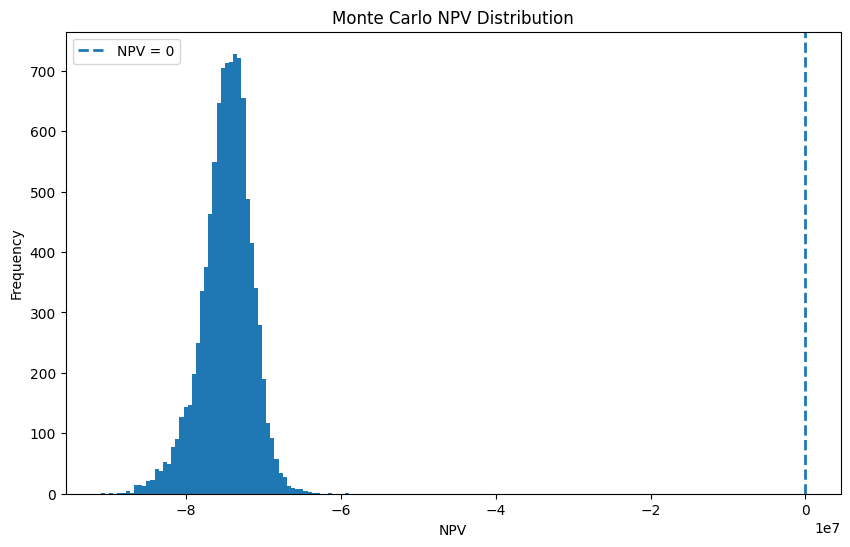

In [91]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    npv_results,
    bins=60
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2,
    label="NPV = 0"
)

plt.xlabel("NPV")
plt.ylabel("Frequency")
plt.title("Monte Carlo NPV Distribution")
plt.legend()

plt.show()

In [92]:
# ============================================================
# SAVE TRAINED MODEL ARTIFACTS FOR APPLICATION INTEGRATION
# ============================================================
#
# The research notebook keeps these objects in memory.
# The FastAPI application cannot access notebook variables
# directly, so we save the trained objects to files.
#
# These files will later be loaded by predictor.py.
# ============================================================

import os
import joblib


# ------------------------------------------------------------
# 1. Define the folder where application model artifacts
#    will be stored.
# ------------------------------------------------------------

MODEL_DIR = "../model"

# Create the folder if it does not already exist.
os.makedirs(MODEL_DIR, exist_ok=True)


# ------------------------------------------------------------
# 2. Save the trained LSTM model.
#
#    The LSTM has already been trained in the notebook.
#    We save the trained weights + architecture so that
#    predictor.py can load the same model later.
# ------------------------------------------------------------

model.save(
    os.path.join(MODEL_DIR, "lstm_model.keras")
)


# ------------------------------------------------------------
# 3. Save the input scaler.
#
#    X_scaler was fitted during model training.
#    We MUST reuse this exact scaler during prediction.
#    We should never fit a new scaler on the user's input.
# ------------------------------------------------------------

joblib.dump(
    X_scaler,
    os.path.join(MODEL_DIR, "X_scaler.pkl")
)


# ------------------------------------------------------------
# 4. Save the target scaler.
#
#    The LSTM predicts scaled cash flow.
#    y_scaler converts that prediction back to the
#    original cash-flow units.
# ------------------------------------------------------------

joblib.dump(
    y_scaler,
    os.path.join(MODEL_DIR, "y_scaler.pkl")
)


# ------------------------------------------------------------
# 5. Save the BBN model.
#
#    The BBN contains the learned probability relationships
#    between project/economic conditions and cash-flow states.
# ------------------------------------------------------------

joblib.dump(
    bbn,
    os.path.join(MODEL_DIR, "bbn_model.pkl")
)


# ------------------------------------------------------------
# 6. Save the BBN discretization boundaries.
#
#    These boundaries were learned from TRAINING data only.
#    The application must reuse these same boundaries when
#    converting new project values into Low / Medium / High.
#
#    This prevents us from recalculating boundaries using
#    future/new project data.
# ------------------------------------------------------------

joblib.dump(
    bbn_bins,
    os.path.join(MODEL_DIR, "bbn_bins.pkl")
)


# ------------------------------------------------------------
# 7. Save the empirical deviation distributions.
#
#    These distributions contain the historical LSTM
#    prediction deviations for:
#
#       Worse
#       Near Expected
#       Better
#
#    Monte Carlo will sample from these distributions
#    according to the BBN probabilities.
# ------------------------------------------------------------

joblib.dump(
    deviation_distributions,
    os.path.join(MODEL_DIR, "deviation_distributions.pkl")
)


# ------------------------------------------------------------
# 8. Confirm that all artifacts were created.
# ------------------------------------------------------------

print("Model artifacts saved successfully:")

for filename in [
    "lstm_model.keras",
    "X_scaler.pkl",
    "y_scaler.pkl",
    "bbn_model.pkl",
    "bbn_bins.pkl",
    "deviation_distributions.pkl"
]:
    print(" -", os.path.join(MODEL_DIR, filename))

Model artifacts saved successfully:
 - ../model\lstm_model.keras
 - ../model\X_scaler.pkl
 - ../model\y_scaler.pkl
 - ../model\bbn_model.pkl
 - ../model\bbn_bins.pkl
 - ../model\deviation_distributions.pkl


In [93]:
# ---------------------------------------------------------------------------
# SHAP BACKGROUND DATA
# ---------------------------------------------------------------------------
#
# SHAP needs representative examples from the same input distribution
# used to train the LSTM.
#
# X_train already contains the historical 3-year sequences used by
# the LSTM during training:
#
#     (samples, 3 years, 3 features)
#
# We keep a smaller representative subset because SHAP does not need
# all training samples to establish its reference distribution.
# ---------------------------------------------------------------------------

import numpy as np
import os


# Use a fixed random seed so that the background dataset is reproducible.
np.random.seed(42)

BACKGROUND_SIZE = 100

# Randomly select representative training sequences.
background_indices = np.random.choice(
    len(X_train),
    size=min(BACKGROUND_SIZE, len(X_train)),
    replace=False
)

shap_background = X_train[background_indices].astype(np.float32)

print("SHAP background shape:", shap_background.shape)

SHAP background shape: (100, 3, 3)


SHAP values shape: (100, 3, 3)
Feature importance shape: (3,)


,Feature,Importance
0,cash_flow,0.259439
1,inflation_rate,0.022703
2,market_growth_rate,0.015427


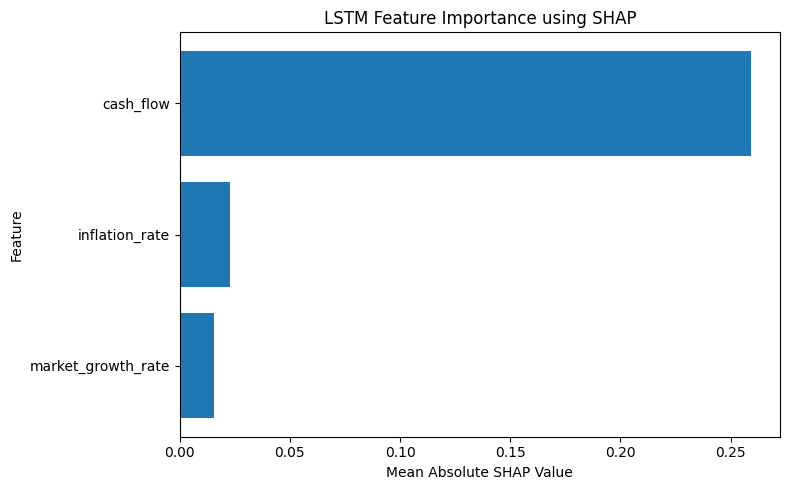

In [95]:
# ============================================================
# LSTM FEATURE IMPORTANCE USING SHAP
# ============================================================

# Remove the final output dimension
# Shape: (100, 3, 3, 1) -> (100, 3, 3)

shap_values = np.squeeze(shap_values, axis=-1)

print("SHAP values shape:", shap_values.shape)

# ------------------------------------------------------------
# Calculate feature importance
# ------------------------------------------------------------

# Average absolute SHAP value across:
#   axis 0 = samples
#   axis 1 = timesteps
#
# Result: one importance value per feature

feature_importance = np.mean(
    np.abs(shap_values),
    axis=(0, 1)
)

print("Feature importance shape:", feature_importance.shape)

# ------------------------------------------------------------
# Create dataframe
# ------------------------------------------------------------

feature_importance_df = pd.DataFrame({
    "Feature": sequence_features,
    "Importance": feature_importance
})

# Sort from most important to least important
feature_importance_df = feature_importance_df.sort_values(
    "Importance",
    ascending=False
)

display(feature_importance_df)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("LSTM Feature Importance using SHAP")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()